In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
import os
import glob
import pandas as pd

data_dir = "../data"
csv_files = sorted(glob.glob(os.path.join(data_dir, "*.csv")))

all_csv = {}

for file_path in csv_files:
    file_name = os.path.splitext(os.path.basename(file_path))[0]
    all_csv[file_name] = pd.read_csv(file_path)
    print(f"Loaded {file_name}: {all_csv[file_name].shape}")

# Optional: expose each CSV as a top-level variable in the notebook
for name, df in all_csv.items():
    globals()[name] = df

list(all_csv.keys())

Loaded ball_by_ball: (200999, 33)
Loaded competition_team_player_mapping: (6413, 6)
Loaded competitions: (141, 4)
Loaded matches: (883, 22)
Loaded playing_eleven: (28381, 9)
Loaded teams: (353, 3)


['ball_by_ball',
 'competition_team_player_mapping',
 'competitions',
 'matches',
 'playing_eleven',
 'teams']

In [19]:
ipl = pd.read_csv('../data/matches.csv')
ipl.head()

,match_id,comp_id,match_number,match_date,stage,venue_id,venue_country,home_team_id,home_team,away_team_id,...,away_team_captain_id,toss_win_team_id,toss_opted,man_of_the_match,first_inn_revised_overs,second_inn_revised_overs,revised_target,knock_out,win_team_id,result
0,13511,1331,1,2022-01-22,League,54,West Indies,28,West Indies,22,...,NaN,28.0,Fielding,0,NaN,NaN,NaN,0,28.0,West Indies Won by 9 Wickets
1,13512,1331,2,2022-01-23,League,54,West Indies,28,West Indies,22,...,478.0,28.0,Fielding,0,NaN,NaN,NaN,0,22.0,England Won by 1 Run
2,13513,1331,3,2022-01-26,League,54,West Indies,28,West Indies,22,...,1596.0,22.0,Fielding,4986,NaN,NaN,NaN,0,28.0,West Indies Won by 20 runs
3,13514,1331,4,2022-01-29,League,54,West Indies,28,West Indies,22,...,1596.0,28.0,Fielding,0,NaN,NaN,NaN,0,22.0,England Won by 34 runs
4,13515,1331,5,2022-01-30,League,54,West Indies,28,West Indies,22,...,NaN,28.0,Batting,0,NaN,NaN,NaN,0,28.0,West Indies Won by 17 runs


/var/folders/hd/dk2fmc5d2415zdb8z1w_4gwc0000gn/T/ipykernel_67572/3286056420.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=matches_per_year.index, y=matches_per_year.values, palette='Blues_d')


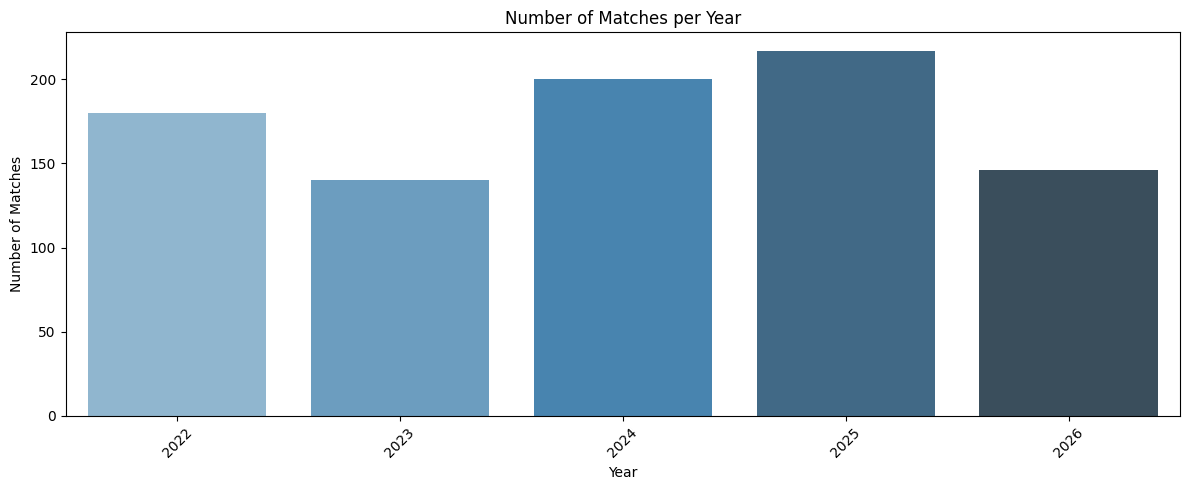

In [20]:
matches_per_year = ipl['match_date'].str[:4].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.barplot(x=matches_per_year.index, y=matches_per_year.values, palette='Blues_d')
plt.title('Number of Matches per Year')
plt.xlabel('Year')
plt.ylabel('Number of Matches')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/var/folders/hd/dk2fmc5d2415zdb8z1w_4gwc0000gn/T/ipykernel_67572/2290733477.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=team_wins_sorted.index, y=team_wins_sorted.values, palette='tab20')


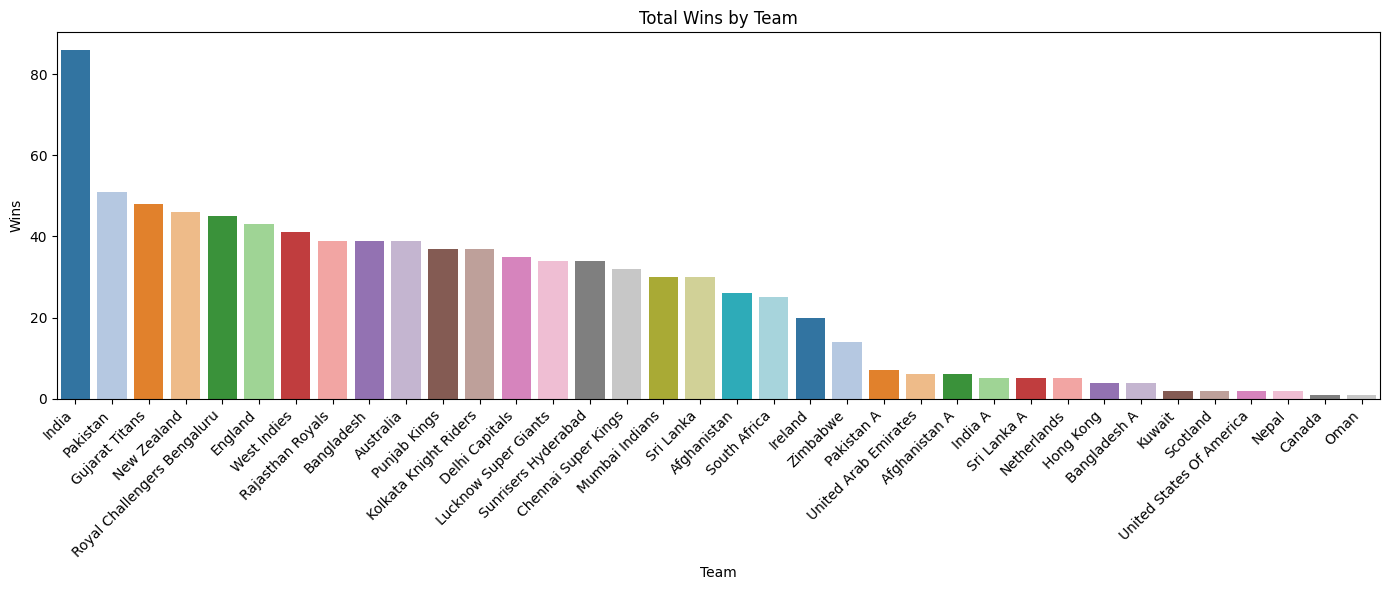

In [21]:
win_team = ipl.apply(lambda r: r['home_team'] if r['win_team_id'] == r['home_team_id'] else r['away_team'], axis=1)
team_wins = win_team.value_counts()
team_matches = pd.concat([ipl['home_team'], ipl['away_team']]).value_counts()

team_wins_sorted = team_wins.sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=team_wins_sorted.index, y=team_wins_sorted.values, palette='tab20')
plt.title('Total Wins by Team')
plt.xlabel('Team')
plt.ylabel('Wins')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Batsman Stats Analysis based on the derived data

/var/folders/hd/dk2fmc5d2415zdb8z1w_4gwc0000gn/T/ipykernel_67572/3971447619.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x='striker_name', y='runs', data=top10, palette='Greens_d')
/var/folders/hd/dk2fmc5d2415zdb8z1w_4gwc0000gn/T/ipykernel_67572/3971447619.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='striker_name', y='runs', data=bottom10, palette='Reds_d')


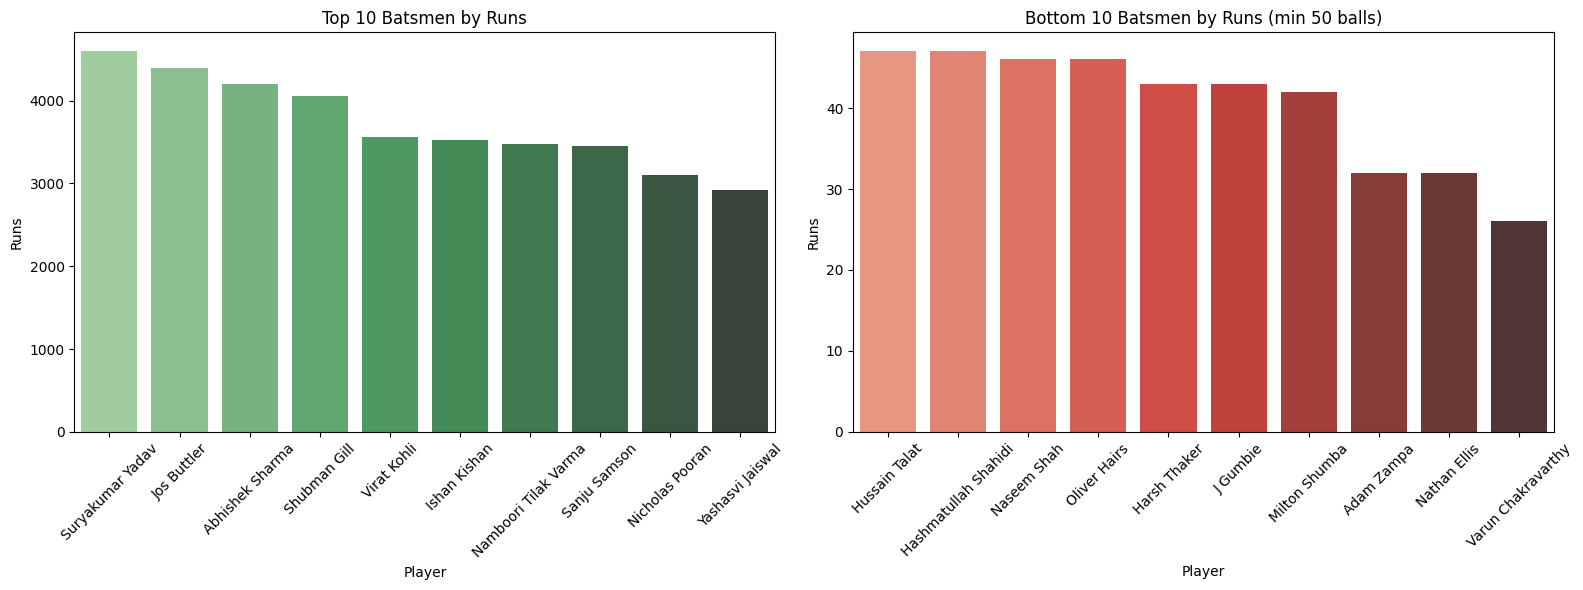


=== TOP 10 BATSMEN ===


,Player,Balls,Runs,4s,6s,Avg,SR
0,Suryakumar Yadav,2850,4595,432,248,38.29,161.23
1,Jos Buttler,2920,4396,431,204,40.33,150.55
2,Abhishek Sharma,2370,4198,404,275,33.58,177.13
3,Shubman Gill,2804,4050,407,142,40.10,144.44
4,Virat Kohli,2545,3567,344,124,44.59,140.16
5,Ishan Kishan,2506,3529,368,157,30.96,140.82
6,Namboori Tilak Varma,2529,3479,267,167,40.45,137.56
7,Sanju Samson,2305,3451,320,187,31.37,149.72
8,Nicholas Pooran,2092,3098,210,222,32.27,148.09
9,Yashasvi Jaiswal,1936,2927,350,129,35.70,151.19



=== BOTTOM 10 BATSMEN ===


,Player,Balls,Runs,4s,6s,Avg,SR
419,Hussain Talat,56,47,4,0,11.75,83.93
420,Hashmatullah Shahidi,58,47,5,0,23.50,81.03
421,Naseem Shah,51,46,4,3,5.75,90.20
422,Oliver Hairs,51,46,6,2,9.20,90.20
423,Harsh Thaker,57,43,3,0,14.33,75.44
424,J Gumbie,53,43,6,0,14.33,81.13
425,Milton Shumba,64,42,4,0,8.40,65.62
426,Adam Zampa,53,32,2,0,3.56,60.38
427,Nathan Ellis,58,32,1,1,4.57,55.17
428,Varun Chakravarthy,51,26,4,0,5.20,50.98


In [22]:
bbb = pd.read_csv('../data/ball_by_ball.csv')
matches = pd.read_csv('../data/matches.csv')
comps = pd.read_csv('../data/competitions.csv')

matches = matches.merge(comps[['comp_id','comp_name','match_format']], on='comp_id')
matches = matches[(matches['match_format']=='T20I') | matches['comp_name'].str.startswith('IPL')]
bbb = bbb[bbb['match_id'].isin(matches['match_id'])]

stats = bbb.groupby(['striker_id','striker_name']).agg(
    balls=('runs','count'),
    runs=('runs','sum'),
    fours=('is_four','sum'),
    sixes=('is_six','sum'),
    dismissals=('is_wicket','sum')
).reset_index()

stats['avg'] = (stats['runs'] / stats['dismissals'].replace(0, float('nan'))).round(2)
stats['sr'] = (stats['runs'] / stats['balls'] * 100).round(2)
stats = stats[stats['balls'] >= 50].sort_values('runs', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10
top10 = stats.head(10)
sns.barplot(ax=axes[0], x='striker_name', y='runs', data=top10, palette='Greens_d')
axes[0].set_title('Top 10 Batsmen by Runs')
axes[0].set_xlabel('Player')
axes[0].set_ylabel('Runs')
axes[0].tick_params(axis='x', rotation=45)

# Bottom 10
bottom10 = stats.tail(10)
sns.barplot(ax=axes[1], x='striker_name', y='runs', data=bottom10, palette='Reds_d')
axes[1].set_title('Bottom 10 Batsmen by Runs (min 50 balls)')
axes[1].set_xlabel('Player')
axes[1].set_ylabel('Runs')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print('\n=== TOP 10 BATSMEN ===')
display(top10[['striker_name','balls','runs','fours','sixes','avg','sr']].rename(columns={'striker_name':'Player','balls':'Balls','runs':'Runs','fours':'4s','sixes':'6s','avg':'Avg','sr':'SR'}))
print('\n=== BOTTOM 10 BATSMEN ===')
display(bottom10[['striker_name','balls','runs','fours','sixes','avg','sr']].rename(columns={'striker_name':'Player','balls':'Balls','runs':'Runs','fours':'4s','sixes':'6s','avg':'Avg','sr':'SR'}))

### Highest Strike Rate Batsmen (min 50 balls)

/var/folders/hd/dk2fmc5d2415zdb8z1w_4gwc0000gn/T/ipykernel_67572/3637576051.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='striker_name', y='sr', data=top_sr, palette='Oranges_d')


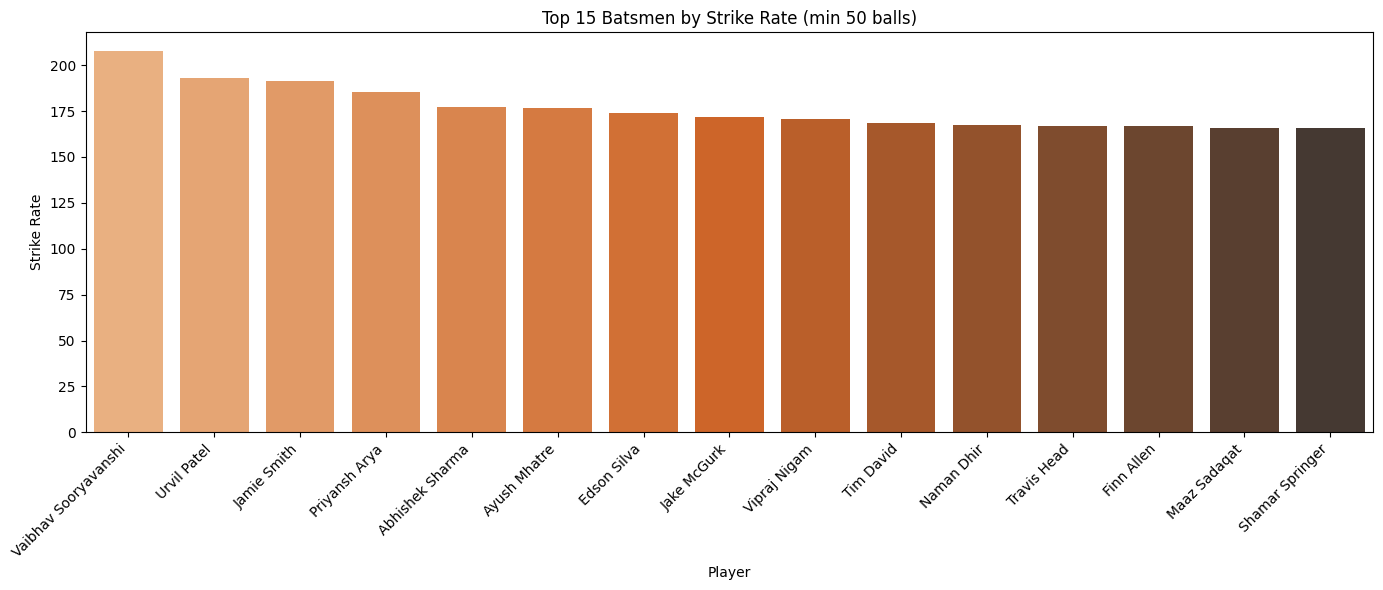

,Player,Balls,Runs,4s,6s,Avg,SR
61,Vaibhav Sooryavanshi,612,1270,101,114,40.97,207.52
229,Urvil Patel,102,197,11,20,19.70,193.14
293,Jamie Smith,68,130,9,10,26.00,191.18
93,Priyansh Arya,491,909,87,63,29.32,185.13
2,Abhishek Sharma,2370,4198,404,275,33.58,177.13
160,Ayush Mhatre,250,441,51,23,36.75,176.40
354,Edson Silva,50,87,3,9,29.00,174.00
150,Jake McGurk,291,500,55,33,22.73,171.82
266,Vipraj Nigam,92,157,17,8,26.17,170.65
23,Tim David,1293,2178,147,162,34.57,168.45


In [23]:
top_sr = stats.sort_values('sr', ascending=False).head(15)

plt.figure(figsize=(14, 6))
sns.barplot(x='striker_name', y='sr', data=top_sr, palette='Oranges_d')
plt.title('Top 15 Batsmen by Strike Rate (min 50 balls)')
plt.xlabel('Player')
plt.ylabel('Strike Rate')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(top_sr[['striker_name','balls','runs','fours','sixes','avg','sr']].rename(columns={'striker_name':'Player','balls':'Balls','runs':'Runs','fours':'4s','sixes':'6s','avg':'Avg','sr':'SR'}))

### Pressure Performer Index — KNN-based Batsman Ranking
Identifies batsmen who perform best in **death overs (last 5 overs of a chase)** when the required run rate is >= 8, weighted by MOM awards.

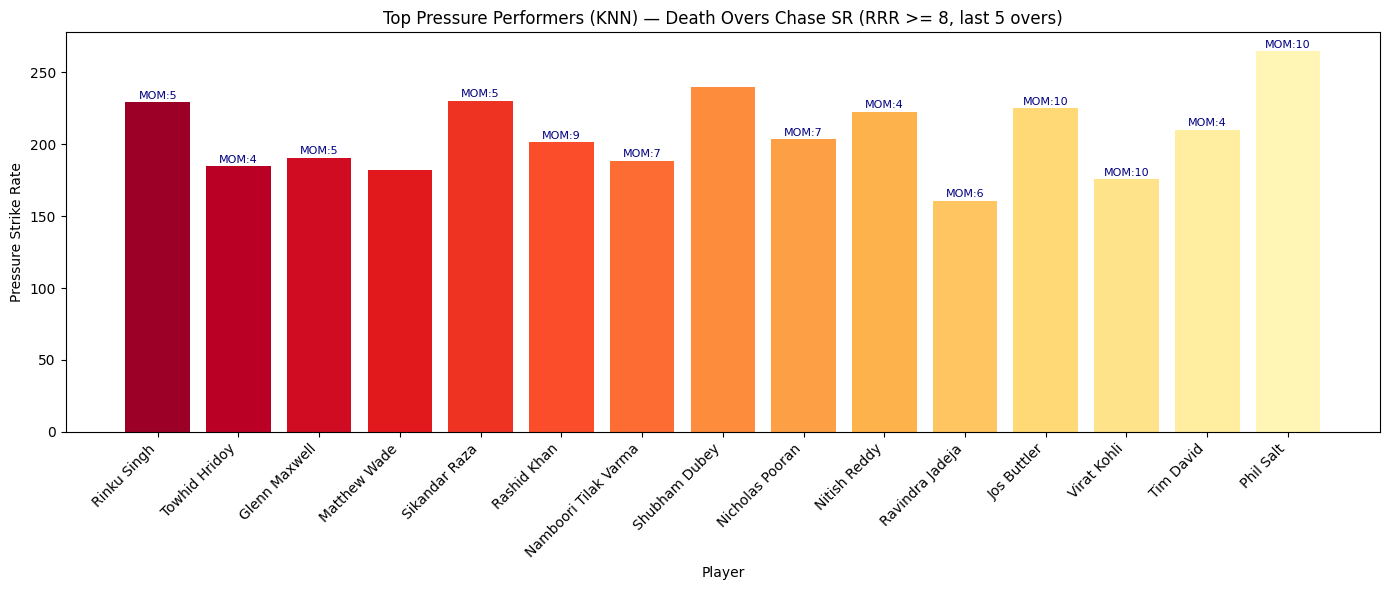

,Rank,Player,Balls,Runs,SR,Avg,4s,6s,MOM,Matches
0,1,Rinku Singh,138,316,228.99,105.33,31,22,5,11
1,2,Towhid Hridoy,78,144,184.62,144.00,11,8,4,8
2,3,Glenn Maxwell,64,122,190.62,122.00,12,7,5,5
3,4,Matthew Wade,100,182,182.00,182.00,15,9,0,8
4,5,Sikandar Raza,56,129,230.36,64.50,8,10,5,7
5,6,Rashid Khan,136,274,201.47,27.40,19,23,9,19
6,7,Namboori Tilak Varma,156,294,188.46,32.67,21,20,7,19
7,8,Shubham Dubey,45,108,240.00,108.00,6,10,0,6
8,9,Nicholas Pooran,116,236,203.45,29.50,17,18,7,15
9,10,Nitish Reddy,53,118,222.64,59.00,6,8,4,8


In [24]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

bbb2 = pd.read_csv('../data/ball_by_ball.csv')
matches2 = pd.read_csv('../data/matches.csv')
comps2 = pd.read_csv('../data/competitions.csv')

# Filter IPL / T20I, no D/L
matches2 = matches2.merge(comps2[['comp_id','comp_name','match_format']], on='comp_id')
matches2 = matches2[
    ((matches2['match_format']=='T20I') | matches2['comp_name'].str.startswith('IPL')) &
    matches2['revised_target'].isna() &
    matches2['first_inn_revised_overs'].isna() &
    matches2['win_team_id'].notna() &
    (matches2['win_team_id'] > 0)
]
bbb2 = bbb2[bbb2['match_id'].isin(matches2['match_id'])].copy()

# Build innings-level target & cumulative score before each ball
inn1_totals = (
    bbb2[bbb2['innings']==1]
    .groupby('match_id')['runs'].sum()
    .rename('inn1_total')
)
bbb2 = bbb2.merge(inn1_totals, on='match_id')
bbb2['target'] = np.where(bbb2['innings']==2, bbb2['inn1_total'] + 1, np.nan)

# Cumulative runs scored BEFORE this ball
bbb2 = bbb2.sort_values(['match_id','innings','innings_ball_num'])
bbb2['cum_runs'] = bbb2.groupby(['match_id','innings'])['runs'].cumsum() - bbb2['runs']

# Legal balls bowled before this ball
bbb2['is_wide'] = (bbb2['extras_type'] == 'wide').astype(int)
bbb2['is_legal'] = 1 - bbb2['is_wide']
bbb2['legal_b'] = bbb2.groupby(['match_id','innings'])['is_legal'].cumsum() - bbb2['is_legal']
bbb2['balls_left'] = (120 - bbb2['legal_b']).clip(lower=1)

# Required run rate
bbb2['runs_needed'] = np.where(bbb2['innings']==2,
                               (bbb2['target'] - bbb2['cum_runs']).clip(lower=0), np.nan)
bbb2['rrr'] = np.where(bbb2['innings']==2,
                       bbb2['runs_needed'] * 6 / bbb2['balls_left'], np.nan)

# Pressure filter: innings 2, last 5 overs (overid >= 16), RRR >= 8, faced balls only
pressure = bbb2[
    (bbb2['innings'] == 2) &
    (bbb2['overid'] >= 16) &
    (bbb2['rrr'] >= 8) &
    (bbb2['extras_type'].isna())
].copy()

# Per-player pressure stats
p_stats = pressure.groupby(['striker_id','striker_name']).agg(
    p_balls   = ('runs', 'count'),
    p_runs    = ('runs', 'sum'),
    p_fours   = ('is_four', 'sum'),
    p_sixes   = ('is_six', 'sum'),
    p_dis     = ('is_wicket', 'sum'),
    p_matches = ('match_id', 'nunique')
).reset_index()

p_stats['p_sr']  = (p_stats['p_runs'] / p_stats['p_balls'] * 100).round(2)
p_stats['p_avg'] = (p_stats['p_runs'] / p_stats['p_dis'].replace(0, np.nan)).round(2)
p_stats = p_stats[p_stats['p_balls'] >= 20].copy()

# MOM count per player
mom_counts = (
    matches2[matches2['man_of_the_match'] > 0]
    .groupby('man_of_the_match').size()
    .reset_index(name='mom_count')
    .rename(columns={'man_of_the_match': 'striker_id'})
)
p_stats = p_stats.merge(mom_counts, on='striker_id', how='left')
p_stats['mom_count'] = p_stats['mom_count'].fillna(0).astype(int)

# KNN: find players most similar to the ideal pressure performer
features = ['p_sr', 'p_avg', 'mom_count', 'p_balls']
X = p_stats[features].fillna(0).values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

ideal = scaler.transform([[
    p_stats['p_sr'].max(),
    p_stats['p_avg'].max(),
    p_stats['mom_count'].max(),
    p_stats['p_balls'].max()
]])

k = min(15, len(p_stats))
knn = NearestNeighbors(n_neighbors=k, metric='euclidean')
knn.fit(X_scaled)
distances, indices = knn.kneighbors(ideal)

top_pressure = p_stats.iloc[indices[0]].copy()
top_pressure['knn_rank'] = range(1, k+1)

# Plot
plt.figure(figsize=(14, 6))
colors = sns.color_palette('YlOrRd', len(top_pressure))[::-1]
bars = plt.bar(top_pressure['striker_name'], top_pressure['p_sr'], color=colors)
plt.title('Top Pressure Performers (KNN) — Death Overs Chase SR (RRR >= 8, last 5 overs)')
plt.xlabel('Player')
plt.ylabel('Pressure Strike Rate')
plt.xticks(rotation=45, ha='right')

for bar, mom in zip(bars, top_pressure['mom_count']):
    if mom > 0:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'MOM:{int(mom)}', ha='center', va='bottom', fontsize=8, color='navy')

plt.tight_layout()
plt.show()

# Table
display(top_pressure[['knn_rank','striker_name','p_balls','p_runs','p_sr','p_avg',
                       'p_fours','p_sixes','mom_count','p_matches']]
        .rename(columns={
            'knn_rank':'Rank','striker_name':'Player','p_balls':'Balls',
            'p_runs':'Runs','p_sr':'SR','p_avg':'Avg',
            'p_fours':'4s','p_sixes':'6s','mom_count':'MOM','p_matches':'Matches'
        }).reset_index(drop=True))


### Anchor Batsmen — High SR, Not Out Under Pressure, Handles Innings After Top-Order Falls
Finds middle-order batsmen (batting order 3-6) who:
- Come in when top-order wickets have fallen early
- Bat through overs 11-20 (last 10 overs)
- Maintain a high strike rate without getting out
- Their team wins the match
- Weighted by MOM awards

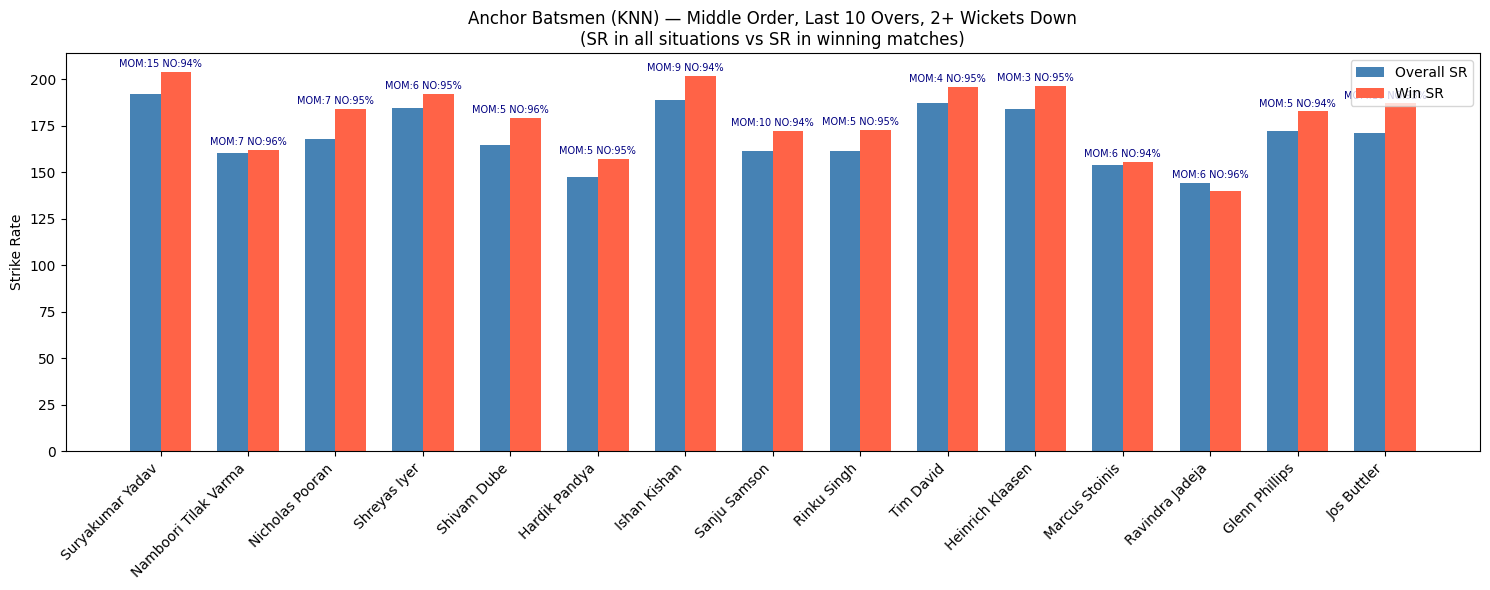

,Rank,Player,Balls,Runs,SR,Avg,NotOut%,WinBalls,WinRuns,WinSR,MOM,Matches
0,1,Suryakumar Yadav,1184,2272,191.89,34.42,94.43,775,1579,203.74,15,80
1,2,Namboori Tilak Varma,1259,2016,160.13,38.04,95.79,692,1121,161.99,7,89
2,3,Nicholas Pooran,929,1560,167.92,31.84,94.73,464,854,184.05,7,69
3,4,Shreyas Iyer,809,1494,184.67,37.35,95.06,528,1015,192.23,6,56
4,5,Shivam Dube,954,1572,164.78,37.43,95.60,497,891,179.28,5,64
5,6,Hardik Pandya,1239,1828,147.54,28.12,94.75,723,1136,157.12,5,90
6,7,Ishan Kishan,363,685,188.71,32.62,94.21,276,557,201.81,9,27
7,8,Sanju Samson,390,630,161.54,26.25,93.85,257,442,171.98,10,32
8,9,Rinku Singh,783,1264,161.43,34.16,95.27,528,911,172.54,5,61
9,10,Tim David,765,1432,187.19,34.10,94.51,507,992,195.66,4,70


In [25]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

bbb3 = pd.read_csv('../data/ball_by_ball.csv')
matches3 = pd.read_csv('../data/matches.csv')
comps3 = pd.read_csv('../data/competitions.csv')

# --- Filter IPL / T20I, no D/L ---
matches3 = matches3.merge(comps3[['comp_id','comp_name','match_format']], on='comp_id')
matches3 = matches3[
    ((matches3['match_format']=='T20I') | matches3['comp_name'].str.startswith('IPL')) &
    matches3['revised_target'].isna() &
    matches3['first_inn_revised_overs'].isna() &
    matches3['win_team_id'].notna() &
    (matches3['win_team_id'] > 0)
]
bbb3 = bbb3[bbb3['match_id'].isin(matches3['match_id'])].copy()
bbb3 = bbb3.sort_values(['match_id','innings','innings_ball_num'])

# --- Attach win_team_id to ball-by-ball ---
bbb3 = bbb3.merge(matches3[['match_id','win_team_id']], on='match_id')

# --- Cumulative wickets fallen BEFORE each ball (per match-innings) ---
bbb3['wkt_int'] = bbb3['is_wicket'].astype(int)
bbb3['wkts_before'] = bbb3.groupby(['match_id','innings'])['wkt_int'].cumsum() - bbb3['wkt_int']

# --- Pressure anchor filter ---
# Innings 1 or 2, overs 11-20 (overid 11-20)
# Batting order 3-6 (middle order / anchor)
# At least 2 top-order wickets already fallen when they face a ball
# Faced ball (no wide)
anchor = bbb3[
    (bbb3['overid'] >= 11) &
    (bbb3['batting_order'].between(3, 6)) &
    (bbb3['wkts_before'] >= 2) &
    (bbb3['extras_type'].isna())
].copy()

# --- Per-player anchor stats ---
a_stats = anchor.groupby(['striker_id','striker_name']).agg(
    a_balls   = ('runs', 'count'),
    a_runs    = ('runs', 'sum'),
    a_fours   = ('is_four', 'sum'),
    a_sixes   = ('is_six', 'sum'),
    a_dis     = ('is_wicket', 'sum'),
    a_matches = ('match_id', 'nunique')
).reset_index()

a_stats['a_sr']       = (a_stats['a_runs'] / a_stats['a_balls'] * 100).round(2)
a_stats['a_avg']      = (a_stats['a_runs'] / a_stats['a_dis'].replace(0, np.nan)).round(2)
a_stats['not_out_pct'] = ((1 - a_stats['a_dis'] / a_stats['a_balls']) * 100).round(2)

# Min 30 anchor balls
a_stats = a_stats[a_stats['a_balls'] >= 30].copy()

# --- Win contribution: balls faced in winning matches ---
win_balls = anchor[anchor['batting_team_id'] == anchor['win_team_id']]
win_contrib = win_balls.groupby('striker_id').agg(
    win_balls = ('runs', 'count'),
    win_runs  = ('runs', 'sum')
).reset_index()
a_stats = a_stats.merge(win_contrib, on='striker_id', how='left')
a_stats['win_balls'] = a_stats['win_balls'].fillna(0).astype(int)
a_stats['win_runs']  = a_stats['win_runs'].fillna(0).astype(int)
a_stats['win_sr']    = (a_stats['win_runs'] / a_stats['win_balls'].replace(0, np.nan) * 100).round(2)

# --- MOM count ---
mom3 = (
    matches3[matches3['man_of_the_match'] > 0]
    .groupby('man_of_the_match').size()
    .reset_index(name='mom_count')
    .rename(columns={'man_of_the_match': 'striker_id'})
)
a_stats = a_stats.merge(mom3, on='striker_id', how='left')
a_stats['mom_count'] = a_stats['mom_count'].fillna(0).astype(int)

# --- KNN: ideal anchor = max SR in wins, max not-out %, max MOM, max balls ---
features = ['win_sr', 'not_out_pct', 'mom_count', 'a_balls']
X = a_stats[features].fillna(0).values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

ideal = scaler.transform([[
    a_stats['win_sr'].max(),
    a_stats['not_out_pct'].max(),
    a_stats['mom_count'].max(),
    a_stats['a_balls'].max()
]])

k = min(15, len(a_stats))
knn = NearestNeighbors(n_neighbors=k, metric='euclidean')
knn.fit(X_scaled)
distances, indices = knn.kneighbors(ideal)

top_anchor = a_stats.iloc[indices[0]].copy()
top_anchor['knn_rank'] = range(1, k+1)

# --- Plot: grouped bar (overall SR vs win SR) ---
x = np.arange(len(top_anchor))
width = 0.35
fig, ax = plt.subplots(figsize=(15, 6))
bars1 = ax.bar(x - width/2, top_anchor['a_sr'],   width, label='Overall SR',  color='steelblue')
bars2 = ax.bar(x + width/2, top_anchor['win_sr'],  width, label='Win SR',      color='tomato')

# Annotate MOM
for i, (mom, not_out) in enumerate(zip(top_anchor['mom_count'], top_anchor['not_out_pct'])):
    label_parts = []
    if mom > 0:
        label_parts.append(f'MOM:{int(mom)}')
    label_parts.append(f'NO:{not_out:.0f}%')
    ax.text(x[i], max(top_anchor['a_sr'].iloc[i], top_anchor['win_sr'].iloc[i]) + 1.5,
            ' '.join(label_parts), ha='center', va='bottom', fontsize=7, color='navy')

ax.set_xticks(x)
ax.set_xticklabels(top_anchor['striker_name'], rotation=45, ha='right')
ax.set_title('Anchor Batsmen (KNN) — Middle Order, Last 10 Overs, 2+ Wickets Down\n(SR in all situations vs SR in winning matches)')
ax.set_ylabel('Strike Rate')
ax.legend()
plt.tight_layout()
plt.show()

# --- Table ---
display(top_anchor[['knn_rank','striker_name','a_balls','a_runs','a_sr','a_avg',
                     'not_out_pct','win_balls','win_runs','win_sr','mom_count','a_matches']]
        .rename(columns={
            'knn_rank':'Rank','striker_name':'Player',
            'a_balls':'Balls','a_runs':'Runs','a_sr':'SR','a_avg':'Avg',
            'not_out_pct':'NotOut%','win_balls':'WinBalls','win_runs':'WinRuns',
            'win_sr':'WinSR','mom_count':'MOM','a_matches':'Matches'
        }).reset_index(drop=True))
